In [1]:
from pathlib import Path
import cv2
import matplotlib.pyplot as plt
import numpy as np
from ultralytics import YOLO

# ================= KONFIGURATION =================
BASE_GT_DIR = Path("./gt_labels_np")  # Pfad zu deinem GT-Hauptordner
IMAGES_DIR = BASE_GT_DIR / "images"  # Ordner mit den Originalbildern
MODEL_PATH = Path(
    "./runs/segment/train-17/weights/best.pt"
)  # Dein trainiertes YOLO-Modell

# Nur die ersten 4 Videos verwenden
TARGET_FOLDERS = [
    "fishvideo_01_0010",
    "fishvideo_02_0010",
    "fishvideo_03_0010",
    "fishvideo_04_0010",
    "fishvideo_05_0010",
    "fishvideo_06_0010",
    "fishvideo_07_0010",
    "fishvideo_08_0010",
    "fishvideo_24_0010",
    "fishvideo_30_0010",
    "fishvideo_38_0010",
    "fishvideo_40_0010",

]

CONF_THRESHOLD = 0.25  # Konfidenz-Schwelle für YOLO
# =================================================

print("Bibliotheken geladen und Pfade gesetzt!")

Bibliotheken geladen und Pfade gesetzt!


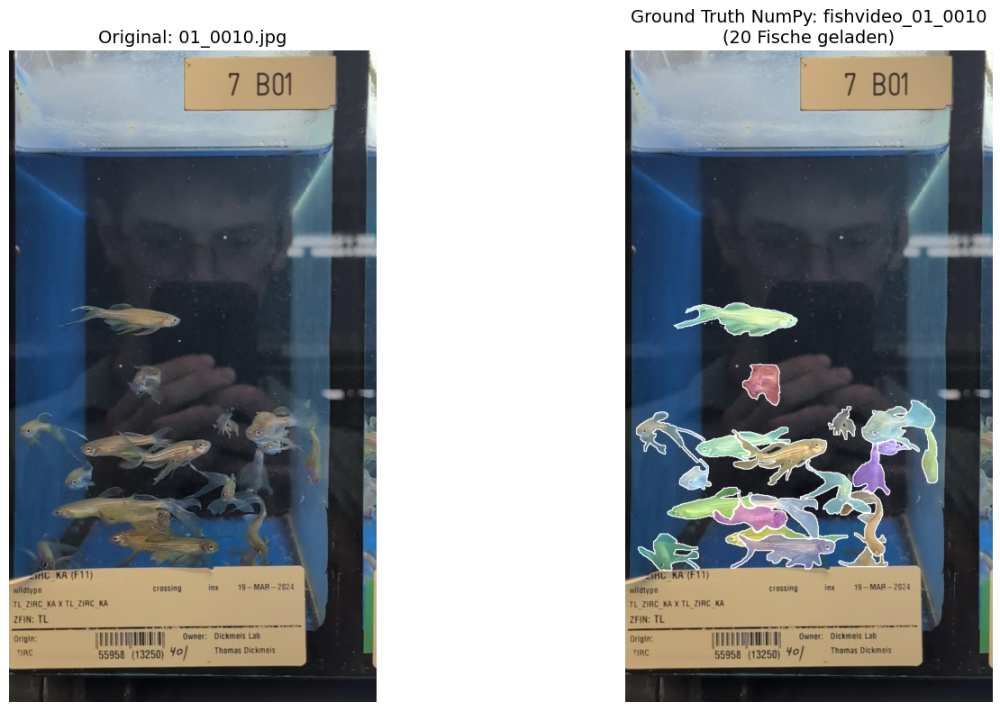

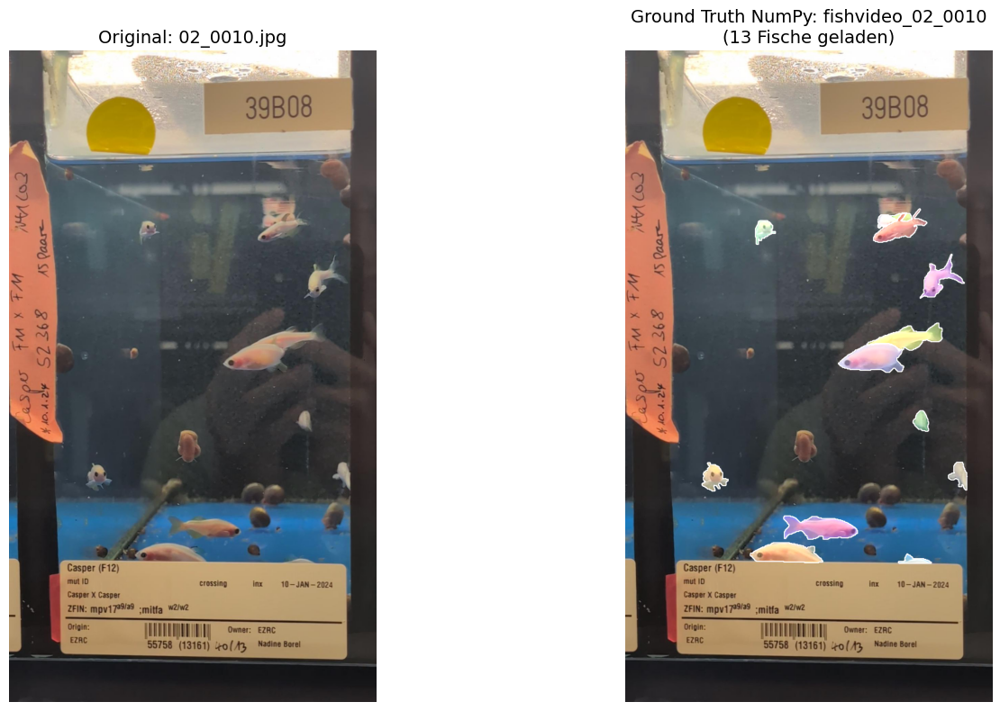

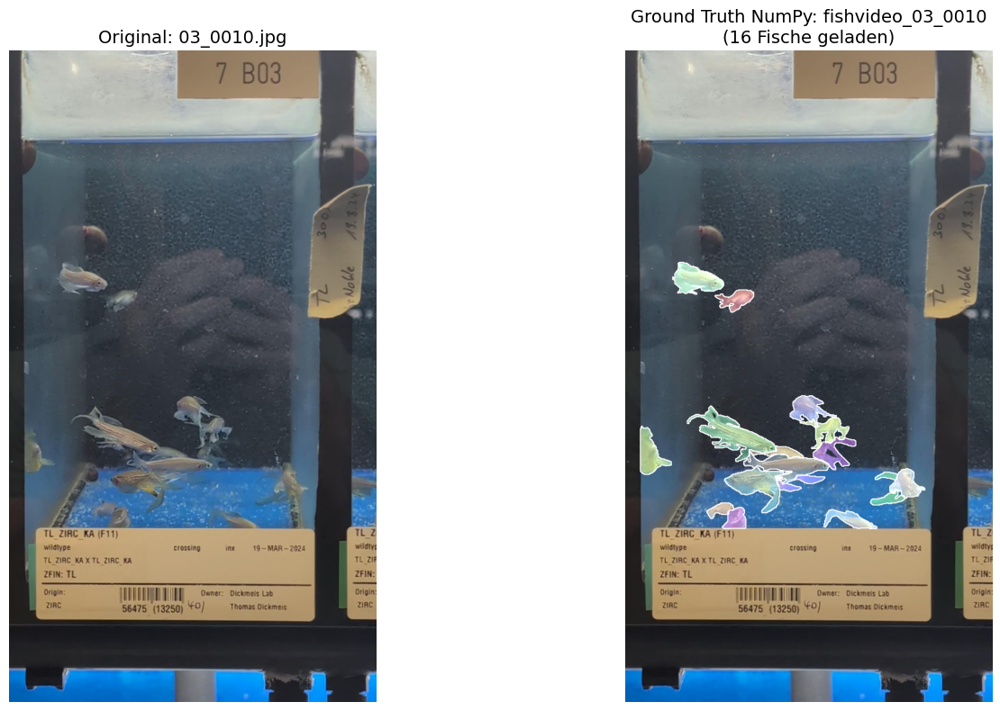

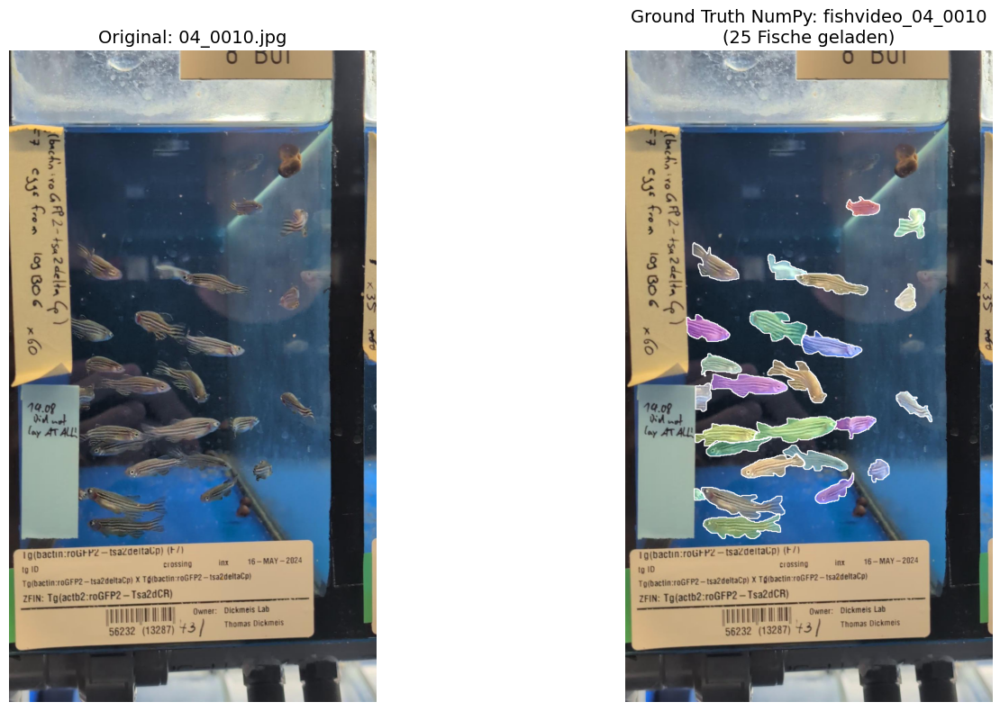

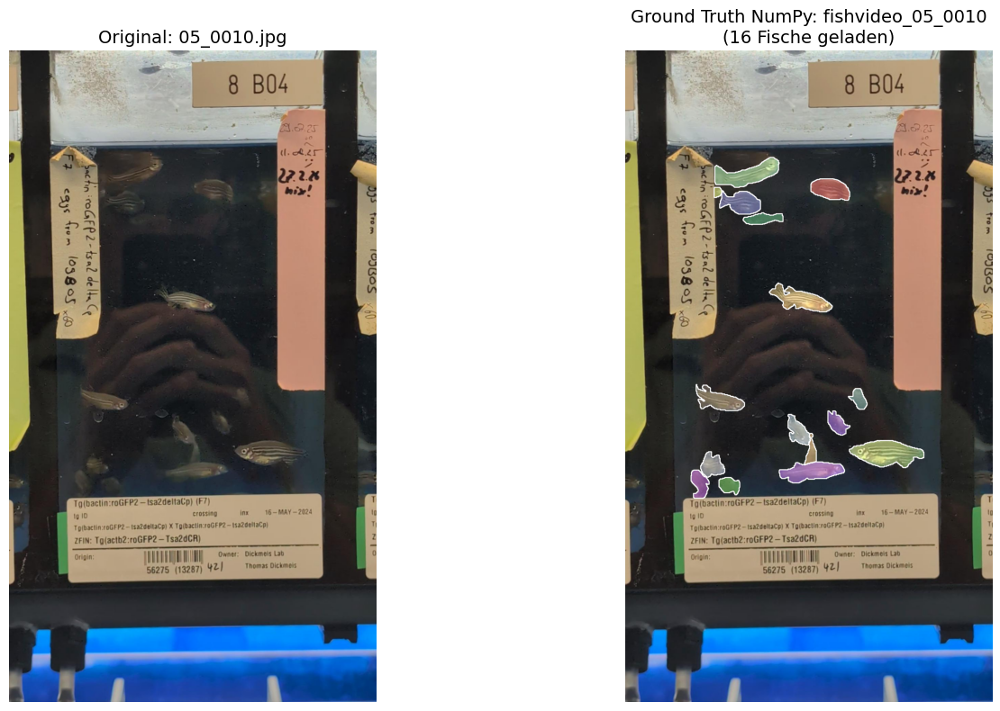

...

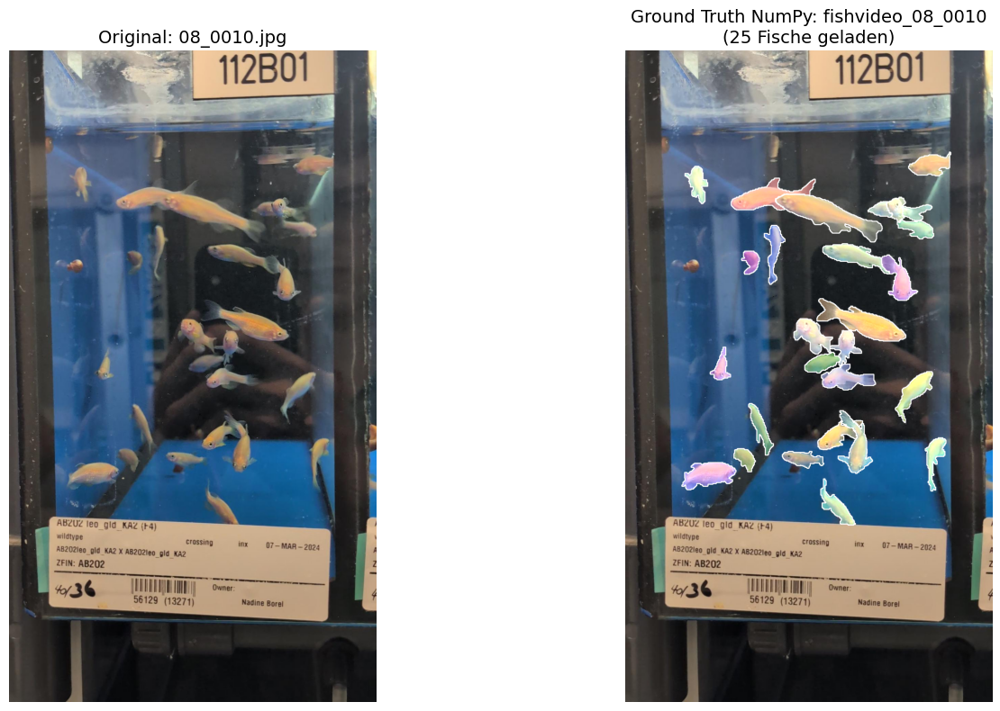

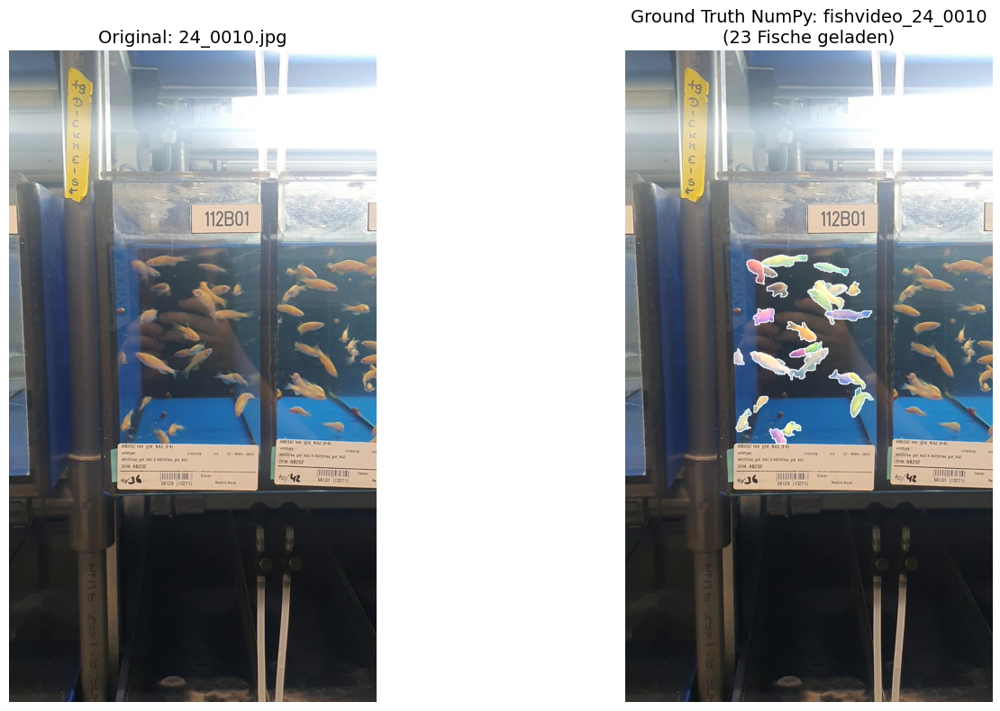

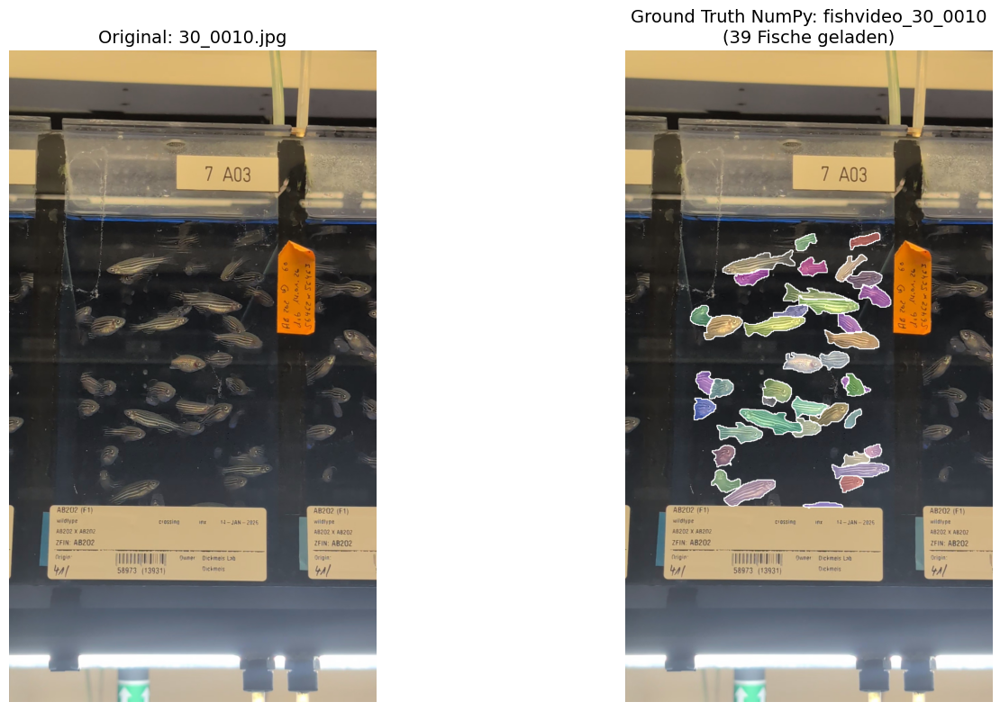

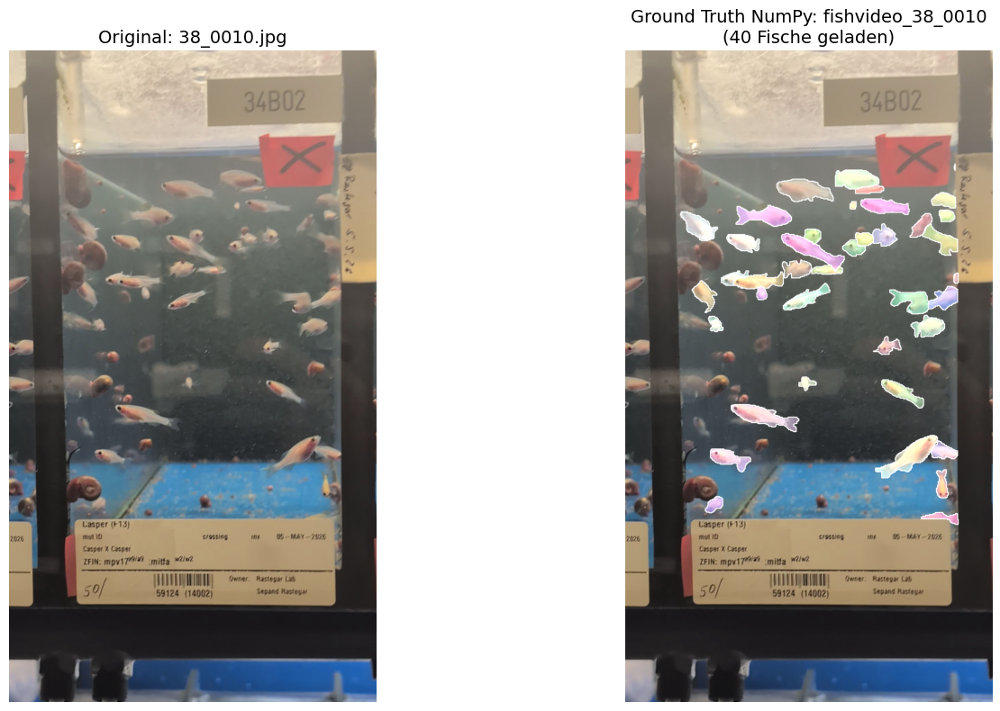

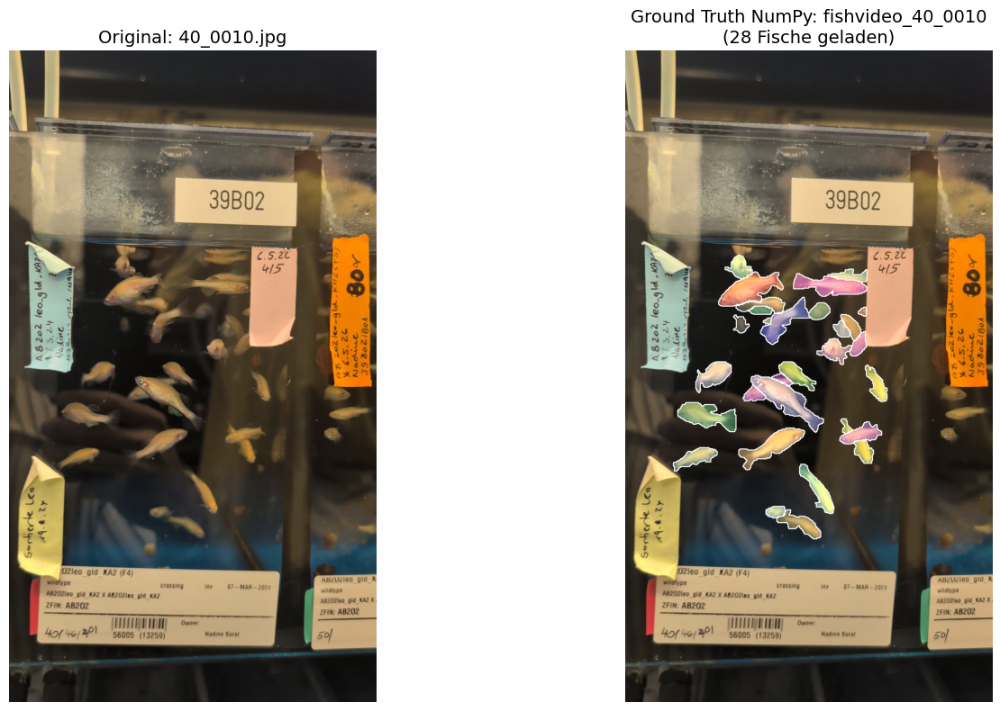

In [3]:
# Hilfsfunktion: Feste, unterscheidbare Farbe pro Fisch-Index
def get_color_for_index(idx):
    np.random.seed(idx * 47 + 5)
    return np.random.randint(60, 255, size=3).tolist()


for folder_name in TARGET_FOLDERS:
    folder_path = BASE_GT_DIR / folder_name
    if not folder_path.exists():
        print(f"[!] Ordner nicht gefunden: {folder_path}")
        continue

    # 1. Passendes Bild finden (sucht nach 01_0010.jpg, fishvideo_01_0010.jpg etc.)
    # Wir extrahieren die Video-ID (z.B. '01_0010')
    short_name = folder_name.replace("fishvideo_", "")
    possible_imgs = list(IMAGES_DIR.glob(f"*{short_name}*.jpg")) + list(
        IMAGES_DIR.glob(f"*{folder_name}*.jpg")
    )

    if not possible_imgs:
        print(f"[!] Kein passendes Bild in {IMAGES_DIR} für {folder_name} gefunden.")
        continue

    img_path = possible_imgs[0]
    img = cv2.imread(str(img_path))
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]

    # 2. Alle .npy/.npz Masken-Dateien in diesem Ordner laden
    npy_files = sorted(list(folder_path.glob("*.npy"))) + sorted(
        list(folder_path.glob("*.npz"))
    )

    overlay = img_rgb.copy()
    num_fishes = 0

    for idx, npy_file in enumerate(npy_files):
        if npy_file.suffix == ".npz":
            data = np.load(npy_file)
            mask = data[list(data.keys())[0]]
        else:
            mask = np.load(npy_file)

        mask = mask.astype(np.uint8)
        if mask.ndim == 3:
            mask = mask.squeeze()

        # Sicherstellen, dass die Maske zur Bildgröße passt
        if mask.shape[:2] != (h, w):
            mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_NEAREST)

        binary_mask = (mask > 0).astype(np.uint8)
        if binary_mask.sum() == 0:
            continue

        num_fishes += 1
        color = get_color_for_index(idx)

        # A) Farbige Füllung (beide Teile des Fisches bekommen exakt dieselbe Farbe!)
        single_mask_layer = np.zeros((h, w, 3), dtype=np.uint8)
        single_mask_layer[binary_mask == 1] = color
        overlay = cv2.addWeighted(overlay, 1.0, single_mask_layer, 0.45, 0)

        # B) Weiße Konturlinien um alle Teile dieser Fisch-Instanz zeichnen
        contours, _ = cv2.findContours(
            binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        cv2.polylines(
            overlay,
            contours,
            isClosed=True,
            color=(255, 255, 255),
            thickness=2,
        )

    # 3. Plot nebeneinander anzeigen
    fig, axes = plt.subplots(1, 2, figsize=(16, 8))

    axes[0].imshow(img_rgb)
    axes[0].set_title(f"Original: {img_path.name}", fontsize=14)
    axes[0].axis("off")

    axes[1].imshow(overlay)
    axes[1].set_title(
        f"Ground Truth NumPy: {folder_name}\n({num_fishes} Fische geladen)",
        fontsize=14,
    )
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

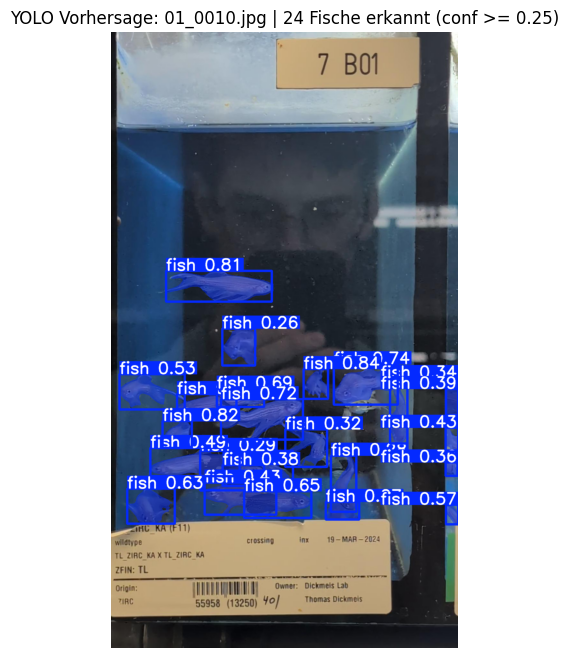

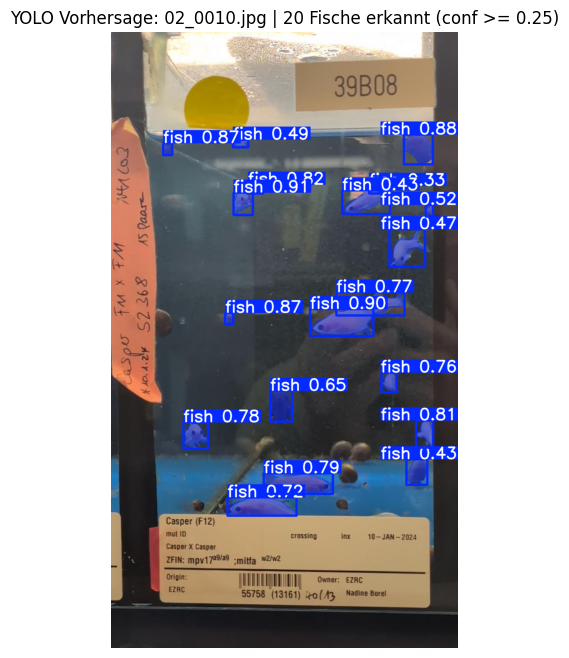

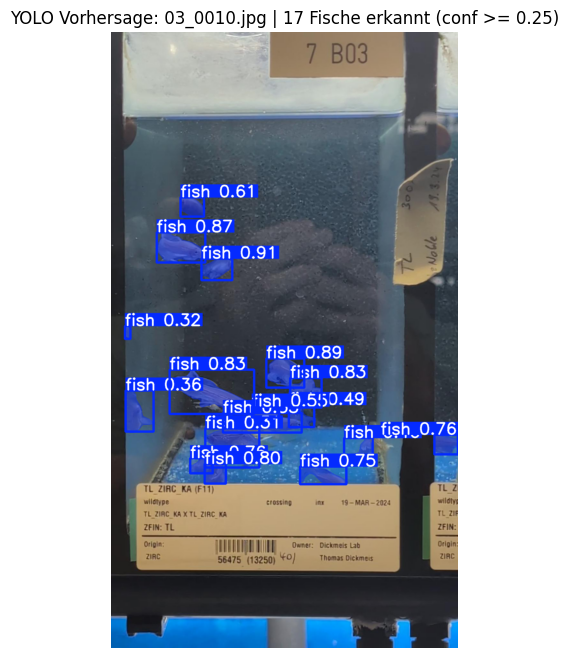

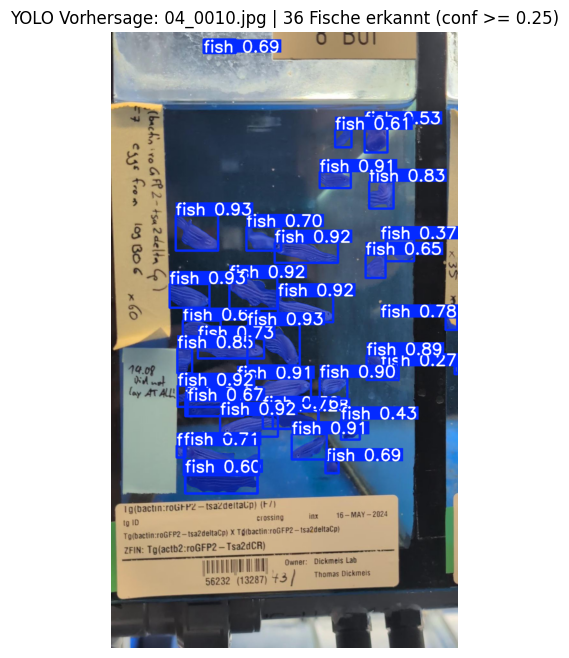

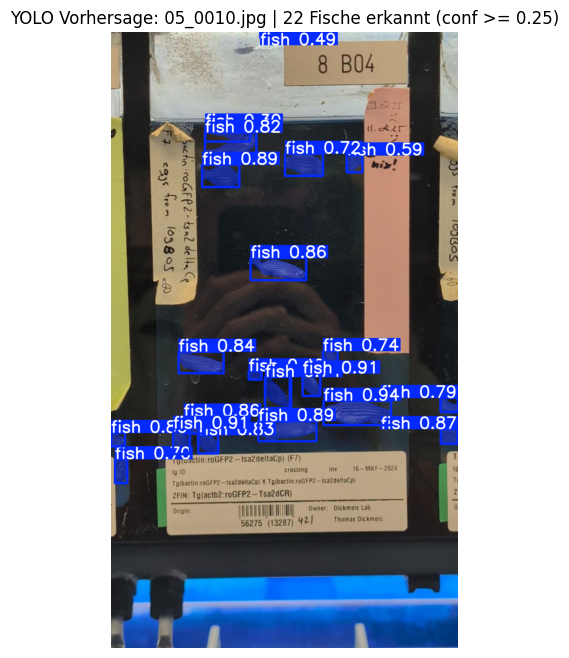

...

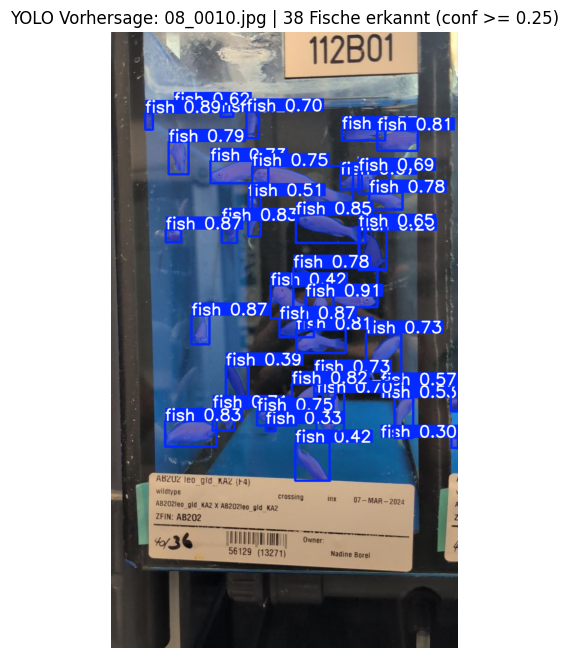

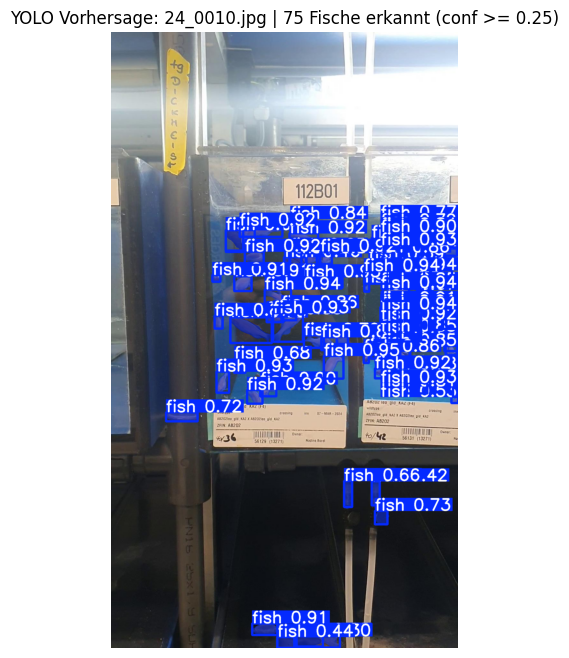

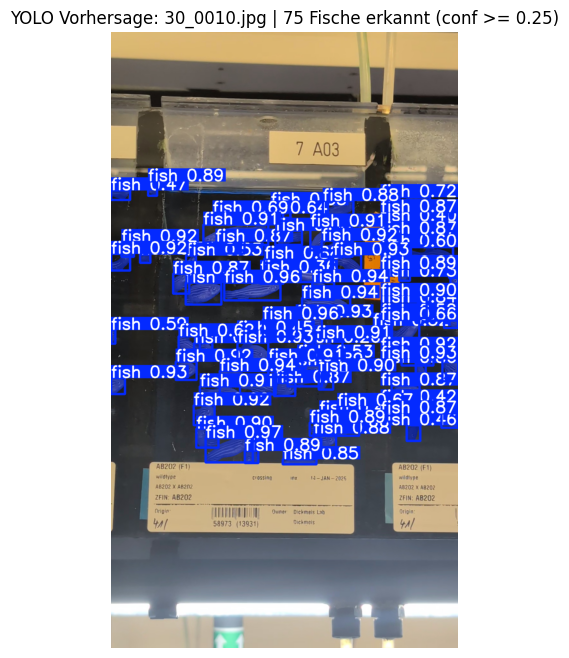

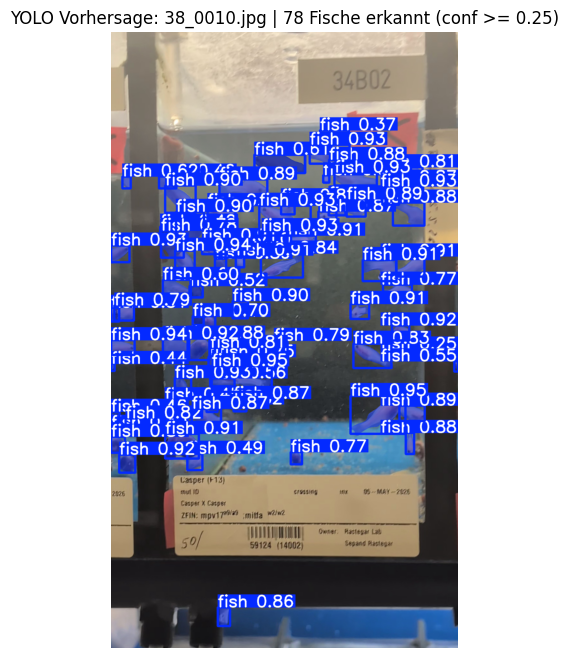

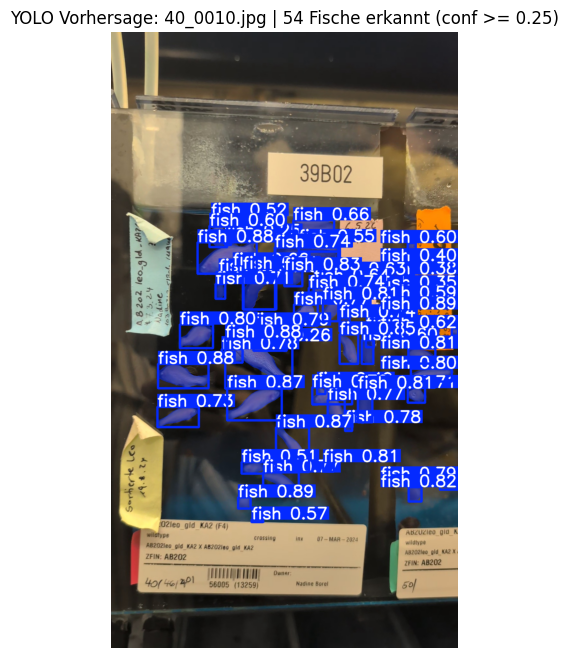

In [4]:
# 1. Trainiertes Modell laden
model = YOLO(MODEL_PATH)

# 2. Inferenz auf den 4 Testbildern ausführen
for folder_name in TARGET_FOLDERS:
    short_name = folder_name.replace("fishvideo_", "")
    possible_imgs = list(IMAGES_DIR.glob(f"*{short_name}*.jpg")) + list(
        IMAGES_DIR.glob(f"*{folder_name}*.jpg")
    )

    if not possible_imgs:
        continue

    img_path = possible_imgs[0]
    img = cv2.imread(str(img_path))
    h, w = img.shape[:2]

    # YOLO Vorhersage ausführen
    results = model.predict(
        source=str(img_path), conf=CONF_THRESHOLD, imgsz=max(h, w), verbose=False
    )

    # Plot mit Masken & Boxen rendern
    pred_plot = results[0].plot()
    pred_plot_rgb = cv2.cvtColor(pred_plot, cv2.COLOR_BGR2RGB)

    num_detected = len(results[0].boxes) if results[0].boxes is not None else 0

    # Anzeige im Notebook
    plt.figure(figsize=(10, 8))
    plt.imshow(pred_plot_rgb)
    plt.title(
        f"YOLO Vorhersage: {img_path.name} | {num_detected} Fische erkannt (conf >= {CONF_THRESHOLD})"
    )
    plt.axis("off")
    plt.show()

In [5]:
import json
from pathlib import Path
import cv2
import numpy as np
from pycocotools import mask as mask_utils
from tidecv import TIDE, datasets
from ultralytics import YOLO

# ================= KONFIGURATION =================
TIDE_OUT_DIR = Path("./tide_output_plots")
TIDE_OUT_DIR.mkdir(parents=True, exist_ok=True)
# =================================================

print("1. Bereite Ground-Truth & Vorhersagen für TIDE vor...")

gt_coco = {
    "images": [],
    "annotations": [],
    "categories": [{"id": 1, "name": "fish", "supercategory": "animal"}],
}
pred_coco = []

ann_id_counter = 1
img_id_counter = 1

model = YOLO(MODEL_PATH)

# Durchlaufe die 4 Test-Ordner
for folder_name in TARGET_FOLDERS:
    folder_path = BASE_GT_DIR / folder_name
    short_name = folder_name.replace("fishvideo_", "")
    possible_imgs = list(IMAGES_DIR.glob(f"*{short_name}*.jpg")) + list(
        IMAGES_DIR.glob(f"*{folder_name}*.jpg")
    )

    if not possible_imgs or not folder_path.exists():
        continue

    img_path = possible_imgs[0]
    img = cv2.imread(str(img_path))
    h, w = img.shape[:2]

    # --- A) Bild zu GT hinzufügen ---
    image_id = img_id_counter
    img_id_counter += 1

    gt_coco["images"].append(
        {
            "id": image_id,
            "file_name": img_path.name,
            "width": w,
            "height": h,
        }
    )

    # --- B) Ground Truth NumPy Masken einlesen ---
    npy_files = sorted(list(folder_path.glob("*.npy"))) + sorted(
        list(folder_path.glob("*.npz"))
    )

    for npy_file in npy_files:
        if npy_file.suffix == ".npz":
            data = np.load(npy_file)
            mask = data[list(data.keys())[0]]
        else:
            mask = np.load(npy_file)

        mask = mask.astype(np.uint8)
        if mask.ndim == 3:
            mask = mask.squeeze()
        if mask.shape[:2] != (h, w):
            mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_NEAREST)

        binary_mask = (mask > 0).astype(np.uint8)
        if binary_mask.sum() == 0:
            continue

        # Maske in COCO RLE / Polygon umwandeln
        rle = mask_utils.encode(np.asfortranarray(binary_mask))
        rle["counts"] = rle["counts"].decode("utf-8")
        bbox = mask_utils.toBbox(rle).tolist()  # [x, y, w, h]
        area = float(mask_utils.area(rle))

        # Konturen für Polygone extrahieren (unterstützt mehrere Teile pro Fisch!)
        contours, _ = cv2.findContours(
            binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
        )
        polygons = []
        for c in contours:
            if len(c) >= 3:
                polygons.append(c.reshape(-1, 2).ravel().tolist())

        gt_coco["annotations"].append(
            {
                "id": ann_id_counter,
                "image_id": image_id,
                "category_id": 1,
                "segmentation": polygons if len(polygons) > 0 else rle,
                "area": area,
                "bbox": bbox,
                "iscrowd": 0,
            }
        )
        ann_id_counter += 1

    # --- C) YOLO Inferenz für dieses Bild ---
    results = model.predict(
        source=str(img_path),
        conf=0.1,  # Niedrige Schwelle für saubere PR-Kurven
        imgsz=max(h, w),
        verbose=False,
    )

    if results[0].masks is not None and results[0].boxes is not None:
        pred_masks = results[0].masks.data.cpu().numpy()
        boxes = results[0].boxes.xywh.cpu().numpy()  # [x_center, y_center, w, h]
        confs = results[0].boxes.conf.cpu().numpy()

        for m, box, conf in zip(pred_masks, boxes, confs):
            m_resized = cv2.resize(
                m, (w, h), interpolation=cv2.INTER_NEAREST
            )
            bin_pred = (m_resized > 0.5).astype(np.uint8)

            if bin_pred.sum() == 0:
                continue

            # Bbox von xywh (center) in xywh (top-left) wandeln
            x_c, y_c, bw, bh = box
            top_x = max(0, x_c - bw / 2)
            top_y = max(0, y_c - bh / 2)

            rle_pred = mask_utils.encode(np.asfortranarray(bin_pred))
            rle_pred["counts"] = rle_pred["counts"].decode("utf-8")

            pred_coco.append(
                {
                    "image_id": image_id,
                    "category_id": 1,
                    "bbox": [
                        float(top_x),
                        float(top_y),
                        float(bw),
                        float(bh),
                    ],
                    "score": float(conf),
                    "segmentation": rle_pred,
                }
            )

# 2. Temporäre JSONs für TIDE abspeichern
gt_json_path = TIDE_OUT_DIR / "tide_gt_temp.json"
pred_json_path = TIDE_OUT_DIR / "tide_pred_temp.json"

with open(gt_json_path, "w") as f:
    json.dump(gt_coco, f)

with open(pred_json_path, "w") as f:
    json.dump(pred_coco, f)

print(
    f"Ground Truth Instanzen: {len(gt_coco['annotations'])} | Vorhersagen: {len(pred_coco)}"
)

# 3. TIDE Initialisieren & Ausführen
print("\n2. Starte TIDE Analyse...")
tide = TIDE()

# Datensätze in TIDE laden
gt_dataset = datasets.COCO(str(gt_json_path))
pred_dataset = datasets.COCOResult(str(pred_json_path))

# Evaluation für Masken & Boxen durchführen
tide.evaluate(gt_dataset, pred_dataset, mode=TIDE.MASK, name="YOLO Mask-Seg")
tide.evaluate(gt_dataset, pred_dataset, mode=TIDE.BOX, name="YOLO Box-Det")

# Zusammenfassung im Notebook ausgeben
print("\n" + "=" * 50)
print("             TIDE FEHLERANALYSE")
print("=" * 50)
tide.summarize()

# Plots generieren und im Ordner speichern
tide.plot(out_dir=str(TIDE_OUT_DIR))
print(
    f"\n[+] TIDE-Plots wurden gespeichert in: {TIDE_OUT_DIR.resolve()}"
)

1. Bereite Ground-Truth & Vorhersagen für TIDE vor...
Ground Truth Instanzen: 295 | Vorhersagen: 597

2. Starte TIDE Analyse...

             TIDE FEHLERANALYSE
-- YOLO Mask-Seg --

mask AP @ 50: 64.05

                         Main Errors
  Type      Cls      Loc     Both     Dupe      Bkg     Miss  
-------------------------------------------------------------
   dAP     0.00     3.51     0.00     0.16    25.89     2.17  

        Special Error
  Type   FalsePos   FalseNeg  
-----------------------------
   dAP      28.03       5.38  

-- YOLO Box-Det --

bbox AP @ 50: 61.08

                         Main Errors
  Type      Cls      Loc     Both     Dupe      Bkg     Miss  
-------------------------------------------------------------
   dAP     0.00     6.61     0.00     0.12    24.45     2.55  

        Special Error
  Type   FalsePos   FalseNeg  
-----------------------------
   dAP      28.03       7.18  



/home/xxbananaopxx/anaconda3/envs/ma1/lib/python3.12/site-packages/tidecv/plotting.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=error_dfs['main'], x='Delta mAP', y='Error Type', ax=ax,
/home/xxbananaopxx/anaconda3/envs/ma1/lib/python3.12/site-packages/tidecv/plotting.py:156: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=error_dfs['special'], x='Error Type', y='Delta mAP', ax=ax,
/home/xxbananaopxx/anaconda3/envs/ma1/lib/python3.12/site-packages/tidecv/plotting.py:161: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['FP', 'FN'])
[ WARN:0@276.180] global loadsave.cpp:1063 


[+] TIDE-Plots wurden gespeichert in: /mnt/c/Users/sinke/Desktop/Masterarbeit/yolo/tide_output_plots
